# Photoneo PhoXi 3D M — Capture Test

Connects to the live Photoneo PhoXi 3D M scanner, triggers a single frame, and displays the texture and depth map with matplotlib.

**Prerequisites:**
- `pip install phoxi-api` (already installed in cnos2)
- PhoXi Control running (`/usr/bin/PhoXiControl`)
- Scanner discovered in PhoXi Control's device list — if network discovery doesn't find it, use `Tools → Add Device via Address` with the scanner's IP

**Depth convention:** PhoXi DepthMap is in **millimetres** — `depth_scale = 1.0`.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

K:
[[2.82421655e+03 0.00000000e+00 1.25717993e+03]
 [0.00000000e+00 2.82397192e+03 1.00944037e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
RGB:   (2064, 2472, 3)
Depth: (2064, 2472)  range 0–810 mm


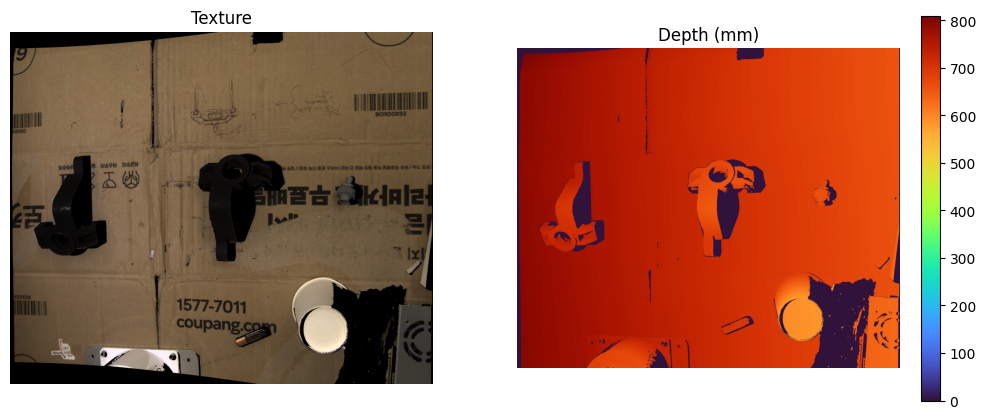

In [2]:
DEPTH_SCALE = 1.0  # PhoXi DepthMap is already in mm

from phoxi_api import PhoXiControl, PhoXiDevice

phc = PhoXiControl()
device_id = next(
    d["id"] for d in phc.get_device_list(refresh=True)
    if d["type"] == "PhoXi3DScan" and not d["file_camera"]
)

with phc.connect(device_id) as device:
    device.set_trigger_mode(PhoXiDevice.TriggerMode.SOFTWARE)
    device.set_frame_settings({"DepthMap": True, "Texture": True})
    device.start_acquisition()
    frame = device.get_frame(frame_id=device.trigger_frame(wait_grabbing_end=True), timeout_ms=60_000)

K = np.array(frame.Info["CameraMatrix"], dtype=np.float32).reshape(3, 3)
depth = np.array(frame.DepthMap, dtype=np.float32).squeeze()
texture = np.array(frame.Texture).squeeze()
rgb = np.stack([texture] * 3, axis=-1) if texture.ndim == 2 else texture
rgb = (rgb / rgb.max() * 255).clip(0, 255).astype(np.uint8)

print(f"K:\n{K}")
print(f"RGB:   {rgb.shape}")
print(f"Depth: {depth.shape}  range {depth.min():.0f}–{depth.max():.0f} mm")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb); axes[0].set_title("Texture"); axes[0].axis("off")
im = axes[1].imshow(depth, cmap="turbo"); axes[1].set_title("Depth (mm)"); axes[1].axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.show()


In [ ]:
import torch

from src.sam6d import SAM6D

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

CAD_PATHS = [
    "/home/joon/Downloads/cad_files/gear/helical_gear.stl",
    "/home/joon/Projects/robot-arm-motion-and-sensing-experiment/notebooks/carrier_v5-Flipper_v7motor_adapter.stl",
    "/home/joon/Projects/robot-arm-motion-and-sensing-experiment/notebooks/carrier_v5-gear_bigger_dummy.stl",
]
MODEL_IDS = ["helical_gear", "carrier_flipper", "carrier_gear"]
TEMPLATE_DIRS = [
    "./sam6d_templates_helical_gear",
    "./sam6d_templates_carrier_flipper",
    "./sam6d_templates_carrier_gear",
]
MESH_COLORS = [
    ( 58,  55,  52),   # helical_gear    — dark warm gray  (~22% luminance)
    ( 12,  52, 160),   # carrier_flipper — dark cobalt blue (~20% luminance)
    ( 12,  52, 160),   # carrier_gear    — same filament as carrier_flipper
]
FLAT_SHADING = True
CAD_PATHS_BY_ID = dict(zip(MODEL_IDS, CAD_PATHS))


/home/joon/.virtualenvs/cnos2/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Using device: cuda


In [4]:
model = SAM6D(
    cad_path=CAD_PATHS,
    model_ids=MODEL_IDS,
    template_dirs=TEMPLATE_DIRS,
    device=DEVICE,

    sam_model_type="vit_h",
    stability_score_thresh=0.94,

    reset_templates=False,
    mesh_color=MESH_COLORS,
    flat_shading=FLAT_SHADING,
    roughness=0.8,
    metallic=0.0,
    light_energy=350,

    det_score_thresh=0.4,
    confidence_thresh=0.4,
    visible_thred=0.15,
    n_template_view=42,
    min_component_area_ratio=0.005,
    mask_overlap_thresh=0.2,
    pose_score_thresh=0.5,

    half_precision=True,
)


load pre-trained checkpoint from: /home/joon/Projects/cnos/checkpoints/mae_pretrain_vit_base.pth


ValueError: string is not a file: `/home/joon/Downloads/cad_files/gear/steering-knuckle-thunder-truck-r1-r.stl`

In [ ]:
results = model(rgb, depth, K, depth_scale=DEPTH_SCALE)

N = len(results["poses"])
print(f"Detections: {N}")
for i in range(N):
    print(
        f"[{i}]  model_id={results['model_ids'][i]!r:22s}"
        f"  ism={results['ism_scores'][i]:.3f}"
        f"  pose_score={results['pose_scores'][i]:.3f}"
    )


Detections: 1
[0]  model_id='helical_gear'          ism=0.626  pose_score=0.624


In [ ]:
from scipy.spatial.transform import Rotation

for i, pose in enumerate(results["poses"]):
    x, y, z = pose["t"]
    roll, pitch, yaw = Rotation.from_matrix(pose["R"]).as_euler("xyz", degrees=True)
    print(
        f"[{i}] {results['model_ids'][i]:16s}"
        f"  XYZ(mm)=({x:8.1f}, {y:8.1f}, {z:8.1f})"
        f"  RPY(deg)=({roll:7.1f}, {pitch:7.1f}, {yaw:7.1f})"
        f"  score={pose['score']:.3f}"
    )


[0] helical_gear      XYZ(mm)=(   -47.8,     -2.4,    717.2)  RPY(deg)=(  136.1,    66.9,    -4.3)  score=0.624


In [ ]:
import json
import subprocess
from datetime import datetime
from scipy.spatial.transform import Rotation

detections = []
for i, pose in enumerate(results["poses"]):
    x, y, z = pose["t"]
    roll, pitch, yaw = Rotation.from_matrix(pose["R"]).as_euler("xyz", degrees=True)
    detections.append({
        "model_id": results["model_ids"][i],
        "xyz_mm": [float(x), float(y), float(z)],
        "rpy_deg": [float(roll), float(pitch), float(yaw)],
        "score": float(pose["score"]),
    })

path = f"/tmp/obj_pose_{datetime.now():%Y%m%d_%H%M%S}.json"
with open(path, "w") as f:
    json.dump(detections, f, indent=2)

subprocess.run(["scp", path, "v@172.30.1.60:~/received/"], check=True)
print(f"Sent {len(detections)} detection(s) -> v@172.30.1.60:~/received/{path.split('/')[-1]}")


Sent 1 detection(s) -> v@172.30.1.60:~/received/obj_pose_20260709_110607.json


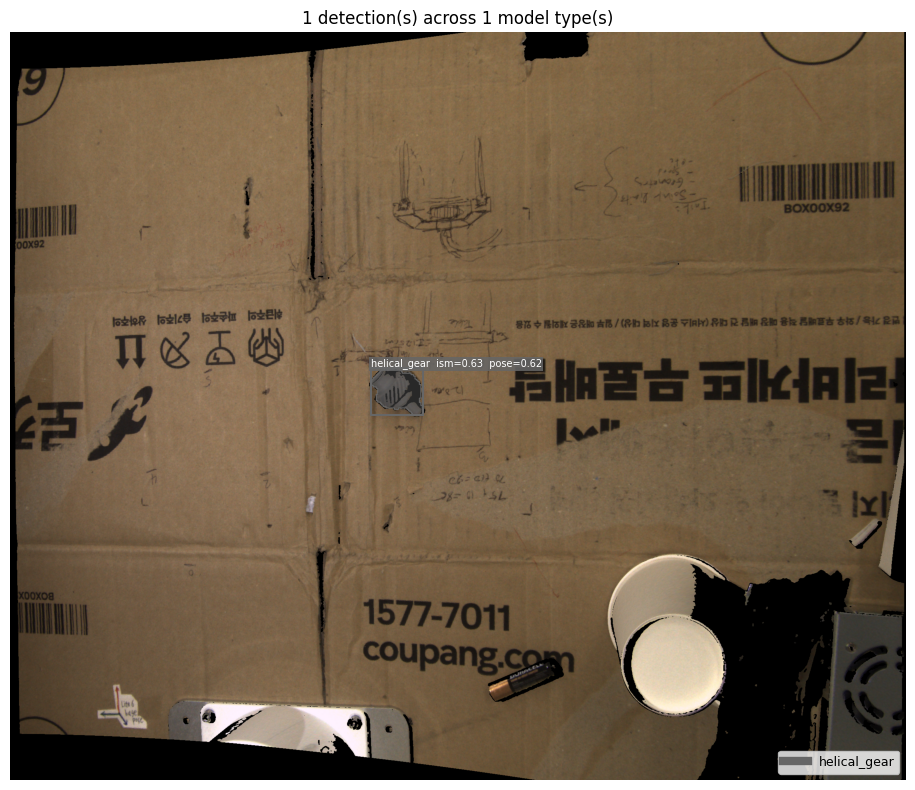

In [ ]:
def visualize_multi_model_detections(rgb, results, alpha=0.4):
    import cv2

    MODEL_PALETTE = {
        "helical_gear":    np.array([102, 102, 102]),
        "carrier_flipper": np.array([ 50, 120, 240]),
        "carrier_gear":    np.array([  0,  89, 242]),
    }
    FALLBACK_COLORS = [
        np.array([220,  50,  50]),
        np.array([ 50, 200,  80]),
        np.array([180,  50, 220]),
        np.array([ 50, 220, 220]),
    ]

    masks       = results["masks"]
    boxes       = results["boxes"]
    ism_scores  = results["ism_scores"]
    pose_scores = results["pose_scores"]
    model_ids   = results.get("model_ids", ["unknown"] * len(masks))

    if len(masks) == 0:
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.imshow(rgb)
        ax.set_title("No detections")
        ax.axis("off")
        plt.show()
        return

    unique_models = sorted(set(model_ids))
    color_map = {}
    fallback_idx = 0
    for mid in unique_models:
        if mid in MODEL_PALETTE:
            color_map[mid] = MODEL_PALETTE[mid]
        else:
            color_map[mid] = FALLBACK_COLORS[fallback_idx % len(FALLBACK_COLORS)]
            fallback_idx += 1

    order   = np.argsort([-m.sum() for m in masks])
    overlay = rgb.copy().astype(float)
    for i in order:
        color = color_map[model_ids[i]]
        overlay[masks[i].astype(bool)] = (
            (1 - alpha) * overlay[masks[i].astype(bool)] + alpha * color
        )

    canvas = overlay.astype(np.uint8)
    for i in order:
        color = color_map[model_ids[i]]
        contours, _ = cv2.findContours(
            masks[i].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(canvas, contours, -1, color.tolist(), 2)

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(canvas)

    for i, (box, ism_s, pose_s, mid) in enumerate(
        zip(boxes, ism_scores, pose_scores, model_ids)
    ):
        x1, y1, x2, y2 = box
        color = color_map[mid] / 255.0
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=1.5, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            x1, y1 - 4,
            f"{mid}  ism={ism_s:.2f}  pose={pose_s:.2f}",
            color="white", fontsize=7,
            bbox=dict(facecolor=color, alpha=0.85, pad=1, edgecolor="none"),
        )

    for mid, color in color_map.items():
        ax.plot([], [], color=color / 255.0, linewidth=6, label=mid)
    ax.legend(loc="lower right", fontsize=9, framealpha=0.8)

    ax.axis("off")
    ax.set_title(f"{len(masks)} detection(s) across {len(unique_models)} model type(s)")
    plt.tight_layout()
    plt.show()


visualize_multi_model_detections(rgb, results)


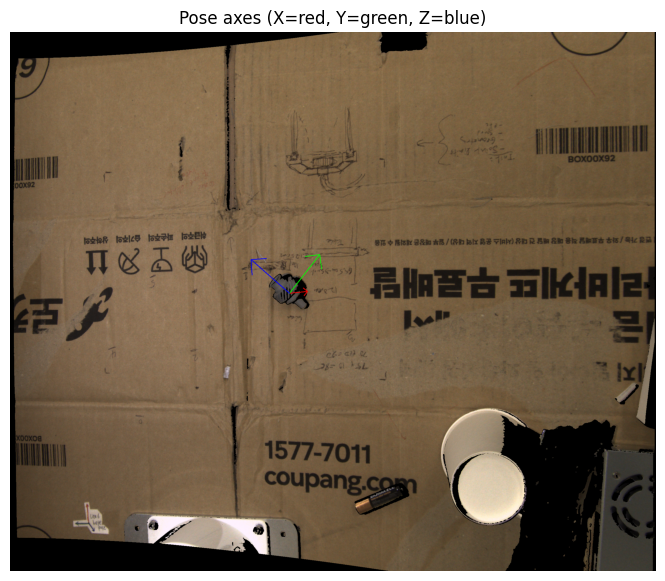

In [ ]:
import cv2

AXIS_LEN_MM = 50
AXIS_COLORS = [(255, 0, 0), (0, 255, 0), (0, 0, 255)]  # X=red, Y=green, Z=blue

fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]

def project(p):
    if p[2] <= 0:
        return None
    return (int(p[0] * fx / p[2] + cx), int(p[1] * fy / p[2] + cy))

canvas = rgb.copy()
for pose in results["poses"]:
    R, t = pose["R"], pose["t"]
    origin = project(t)
    if origin is None:
        continue
    for axis, color in zip(np.eye(3), AXIS_COLORS):
        tip = project(t + R @ (axis * AXIS_LEN_MM))
        if tip:
            cv2.arrowedLine(canvas, origin, tip, color, 2, tipLength=0.3)

plt.figure(figsize=(10, 7))
plt.imshow(canvas)
plt.axis("off")
plt.title("Pose axes (X=red, Y=green, Z=blue)")
plt.show()


In [ ]:
import subprocess
from datetime import datetime
from PIL import Image

img_path = f"/tmp/obj_pose_{datetime.now():%Y%m%d_%H%M%S}.png"
Image.fromarray(canvas).save(img_path)

subprocess.run(["scp", img_path, "v@172.30.1.60:~/received/"], check=True)
print(f"Sent image -> v@172.30.1.60:~/received/{img_path.split('/')[-1]}")


Sent image -> v@172.30.1.60:~/received/obj_pose_20260709_110610.png
